# TabPFN via `lazy` on BTSbot metadata

A test of a tabular foundation model ([lazy-tfm](https://lazy-tfm.readthedocs.io), TabPFN backend) as a
metadata-only alternative to `um_nn`. It runs on BTSbot's existing train/val/test candidate CSVs
(`{split}_cand_{version}_N{N_MAX}.csv`), or any CSVs with a `label` column and the metadata columns, and reports
both alert-level metrics and BTSbot's policy-based (per-source) metrics from `policy_metrics.py`, the same code
`val.py` uses. **Change the dataset and context in the Settings cell below.**

**Environment:** the `BTSbot-tfm` kernel (Python 3.13, `pip install -e .` and `pip install 'lazy-tfm[tabpfn]'`).

**Note:** `lazy` does **regression only**. It predicts a full conditional density $p(y\mid x)$. BTSbot is a binary
classifier, so here we regress on the 0/1 `label` and use the predictive **mean** as the score. For a target in $\{0,1\}$,
$\mathbb{E}[y\mid x] = P(y{=}1\mid x)$.

TabPFN is in-context: `fit` only stores the training rows (the "context"), so there's no training loop. The cost is in
prediction, which scales with context size × number of rows predicted.

In [1]:
import gc
import json
import os
import warnings

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import accuracy_score, precision_score, recall_score, roc_auc_score, roc_curve

import lazy
from policy_metrics import compute_policy_performance_fast

# tabpfn emits many DeprecationWarnings about its own internal imports
warnings.filterwarnings("ignore", category=DeprecationWarning, module="tabpfn")
print("lazy", lazy.__version__)

lazy 0.6.0


/Users/nabeelr/miniforge3/envs/BTSbot-tfm/lib/python3.13/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## Settings
Everything you'd normally change is here. Paths are relative to `btsbot/`.

In [2]:
# --- Dataset ----------------------------------------------------------------
DATA_DIR = "data"              # on the cluster: f"/scratch/nrc5378/BTSbot_training_{DATASET_VERSION}/data"
DATASET_VERSION = "v11"     # e.g. "v11", "v11sub", "v10"
N_MAX = 100
EVAL_SPLIT = "val"             # "val" or "test"

SPLIT_PATHS = {
    split: f"{DATA_DIR}/{split}_cand_{DATASET_VERSION}_N{N_MAX}.csv" for split in ("train", "val", "test")
}
# Or point a split at any CSV directly, e.g.:
# SPLIT_PATHS["val"] = "data/val_cand_v11_N100.csv"

CONFIG_PATH = "train_configs/prod_config.json"  # metadata_cols are read from here

# --- Model ----------------------------------------------------------------------
MODEL_VERSION = "v3.5-fast"    # CPU-friendly; "v3.5" is larger and wants a GPU
DEVICE = "auto"                # "auto" picks cuda > mps > cpu; or set "cuda", "mps", "cpu"
N_ESTIMATORS = 1               # TabPFN ensemble members per fit (per bag when bagging)
SEED = 2

# --- Context (what TabPFN conditions on) -------------------------------------------
# Chosen by source: a selected source always brings all of its train alerts. Defaults use all of train.
CONTEXT_SOURCES = None   # None = all train sources. int = a random subset of this many sources
BAG_SOURCES = 700        # None = no bagging. int = each bag is every alert of this many random sources
N_BAGS = 8               # only with BAG_SOURCES: one TabPFN fit per bag, scores averaged
# Example runs (v11 train averages ~29 alerts per source):
#   one ~20k-alert context:        CONTEXT_SOURCES = 700
#   source bagging over all train: BAG_SOURCES, N_BAGS, N_ESTIMATORS = 700, 90, 1

## Data
Loads the existing `train` split and `EVAL_SPLIT` for evaluation. Evaluation always uses the full split, so every
source's complete alert history is there for the policy metrics. The context is all of `train` unless you set
`CONTEXT_SOURCES`; sources (never individual alerts) are what get subsampled or bagged.

TabPFN caps the alerts in one fit at 5,000 on CPU and 1,000,000 on a GPU (CUDA or Apple MPS; TabPFN v3+). That's
the whole context, or the largest bag when bagging. This cell raises an error rather than fitting if that's over the
limit for the device. In practice GPU memory runs out far sooner: on a 32 GB Mac (MPS), one fit on 20k alerts used
~11 GiB and 40k didn't fit. Bags are fit one at a time with memory freed in between, so memory follows the largest
bag, while time grows with `N_BAGS × N_ESTIMATORS × bag size`.

In [3]:
import torch

if DEVICE == "auto":
    device = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
else:
    device = DEVICE

with open(CONFIG_PATH) as f:
    metadata_cols = json.load(f)["metadata_cols"]

train_path, eval_path = SPLIT_PATHS["train"], SPLIT_PATHS[EVAL_SPLIT]
train = pd.read_csv(train_path)
evaluation = pd.read_csv(eval_path)
eval_name = os.path.basename(eval_path)

for name, d in [("train", train), (EVAL_SPLIT, evaluation)]:
    missing = set(metadata_cols + ["label", "objectId"]) - set(d.columns)
    if missing:
        raise ValueError(f"{name} split is missing columns: {sorted(missing)}")
    print(f"{name:6s} {len(d):>9,} alerts  {d.objectId.nunique():>6,} sources  BTS frac {d.label.mean():.3f}"
          f"  ({os.path.basename(SPLIT_PATHS[name])})")

rng = np.random.default_rng(SEED)
train_sources = train.objectId.unique()
if CONTEXT_SOURCES is None:
    context = train
else:
    if CONTEXT_SOURCES > len(train_sources):
        raise ValueError(f"CONTEXT_SOURCES={CONTEXT_SOURCES:,} but train only has {len(train_sources):,} sources")
    context = train[train.objectId.isin(rng.choice(train_sources, CONTEXT_SOURCES, replace=False))]

bags = None  # list of context row labels, one per bag
if BAG_SOURCES is not None:
    context_sources = context.objectId.unique()
    if BAG_SOURCES > len(context_sources):
        raise ValueError(f"BAG_SOURCES={BAG_SOURCES:,} but the context only has {len(context_sources):,} sources")
    bags = [
        context.index[context.objectId.isin(rng.choice(context_sources, BAG_SOURCES, replace=False))]
        for _ in range(N_BAGS)
    ]

# TabPFN v3+ limits on alerts per fit: 5,000 on CPU (upstream's default), 1,000,000 on GPU (declared by the checkpoint)
max_fit_rows = 5_000 if device == "cpu" else 1_000_000
fit_rows = max(len(b) for b in bags) if bags else len(context)
if fit_rows > max_fit_rows:
    what = f"the largest bag has {fit_rows:,} alerts" if bags else f"the context has {fit_rows:,} alerts"
    raise ValueError(
        f"{what} but TabPFN {MODEL_VERSION} takes at most {max_fit_rows:,} per fit on {device.upper()}. "
        "Set CONTEXT_SOURCES or BAG_SOURCES lower" + (", or run on a GPU (CUDA or MPS)." if device == "cpu" else ".")
    )

print(f"\n{len(metadata_cols)} metadata features on {device}; context {context.objectId.nunique():,} sources, "
      f"{len(context):,} alerts" + (" (random subset of train)" if CONTEXT_SOURCES is not None else " (all of train)"))
if bags is None:
    print(f"one fit, {N_ESTIMATORS} members, on all {len(context):,} context alerts (limit {max_fit_rows:,})")
    run_desc = f"{context.objectId.nunique():,} sources / {len(context):,} alerts"
else:
    used = context.loc[np.unique(np.concatenate(bags))]
    sizes = [len(b) for b in bags]
    print(f"{N_BAGS} bags x {BAG_SOURCES:,} sources ({min(sizes):,}-{max(sizes):,} alerts; limit {max_fit_rows:,}), "
          f"{N_ESTIMATORS} members each; {used.objectId.nunique() / context.objectId.nunique():.1%} of context sources "
          f"({len(used) / len(context):.1%} of alerts) are in at least one bag")
    run_desc = f"{N_BAGS} bags x {BAG_SOURCES:,} sources"

X_ctx, y_ctx = context[metadata_cols], context.label.astype(float)
X_eval, y_eval = evaluation[metadata_cols], evaluation.label.values

train    591,903 alerts  20,756 sources  BTS frac 0.363  (train_cand_v11_N100.csv)
val       84,441 alerts   2,281 sources  BTS frac 0.333  (val_cand_v11_N100.csv)

25 metadata features on mps; context 20,756 sources, 591,903 alerts (all of train)
8 bags x 700 sources (18,099-21,166 alerts; limit 1,000,000), 1 members each; 24.0% of context sources (23.7% of alerts) are in at least one bag


## Fit TabPFN and score the evaluation alerts
Runs on the device chosen above: CUDA (e.g. the cluster) and CPU work with `lazy` as-is. **Apple MPS** needs one
patch: `lazy` 0.6.0 casts TabPFN's output logits to float64 *before* moving them to the CPU, and MPS has no float64,
so `predict` crashes. The patch moves the logits to the CPU first; nothing else changes (on the same context, MPS
scores match CPU to ~1e-5). It's only applied when running on MPS.

With bagging, each bag is a separate TabPFN fit (seeded differently) and the score is the average of the bags'
predictive means, which is the mean of the bags' averaged density. Each bag's model is freed before the next.

The first run downloads the weights and shows a `LicenseWarning`: TabPFN-3.5 weights are under a **non-commercial**
license.

In [4]:
%%time
if device == "mps":
    import lazy.models.tabpfn as _lazy_tabpfn

    if not getattr(_lazy_tabpfn.bucket_masses, "_mps_safe", False):
        _bucket_masses = _lazy_tabpfn.bucket_masses

        def _bucket_masses_mps_safe(output, *args, **kwargs):
            # MPS has no float64: move logits to the CPU before lazy casts them with .double()
            return _bucket_masses({**output, "logits": output["logits"].detach().cpu()}, *args, **kwargs)

        _bucket_masses_mps_safe._mps_safe = True
        _lazy_tabpfn.bucket_masses = _bucket_masses_mps_safe


def make_model(seed):
    return lazy.LazyModel("tabpfn", version=MODEL_VERSION, device=device, random_state=seed, n_estimators=N_ESTIMATORS)


def free_device_memory():
    gc.collect()
    if device == "cuda":
        torch.cuda.empty_cache()
    elif device == "mps":
        torch.mps.empty_cache()


if bags is None:
    model = make_model(SEED)
    model.fit(X_ctx, y_ctx)
    tfm_score = model.predict(X_eval, method="mean")
else:
    model = None  # one model per bag, each freed after scoring
    tfm_score = np.zeros(len(X_eval))
    for i, rows in enumerate(bags):
        bag_model = make_model(SEED + i)
        bag_model.fit(X_ctx.loc[rows], y_ctx.loc[rows])
        tfm_score += bag_model.predict(X_eval, method="mean") / len(bags)
        del bag_model
        free_device_memory()
        if (i + 1) % max(1, len(bags) // 10) == 0 or i + 1 == len(bags):
            print(f"bag {i + 1}/{len(bags)} done", flush=True)

# Predictive mean ~ P(BTS | metadata). Clip tiny numerical excursions outside [0, 1].
evaluation = evaluation.assign(tfm_score=np.clip(tfm_score, 0, 1))

# Scores to evaluate: {display name: column}. The production BTSbot score is only present in some files
# (e.g. example_data); it's compared when it is.
scores = {f"TabPFN {MODEL_VERSION}, {run_desc}": "tfm_score"}
if "expected_scores" in evaluation.columns:
    scores["BTSbot prod (images + metadata)"] = "expected_scores"
evaluation[["objectId", "label", *scores.values()]].head(10)

bag 1/8 done


bag 2/8 done


bag 3/8 done


bag 4/8 done


bag 5/8 done


bag 6/8 done


bag 7/8 done


bag 8/8 done


CPU times: user 40.8 s, sys: 25 s, total: 1min 5s
Wall time: 5min 56s


,objectId,label,tfm_score
0,ZTF18acixixu,0,0.009378
1,ZTF19acylgic,1,0.998055
2,ZTF24abislzl,0,0.123450
3,ZTF23aaejixk,0,0.002927
4,ZTF20achtkxi,0,0.001819
5,ZTF18abktpvm,0,0.003826
6,ZTF18abmanuy,0,0.014203
7,ZTF18absrcps,0,0.072851
8,ZTF20aazswwk,0,0.002121
9,ZTF21achfgmf,0,0.051788


## Alert-level metrics
At a 0.5 threshold. `BTSbot prod` (if present) is the production `mm_cnn`, which uses **images + metadata**, so
it's a reference rather than a like-for-like comparison with a metadata-only model.

In [5]:
def summarize(y, s, thresh=0.5):
    pred = s >= thresh
    return {
        "AUC": roc_auc_score(y, s),
        "accuracy": accuracy_score(y, pred),
        "precision": precision_score(y, pred),
        "recall": recall_score(y, pred),
    }

pd.DataFrame({name: summarize(y_eval, evaluation[col]) for name, col in scores.items()}).T.round(4)

,AUC,accuracy,precision,recall
"TabPFN v3.5-fast, 8 bags x 700 sources",0.9907,0.9627,0.9713,0.915


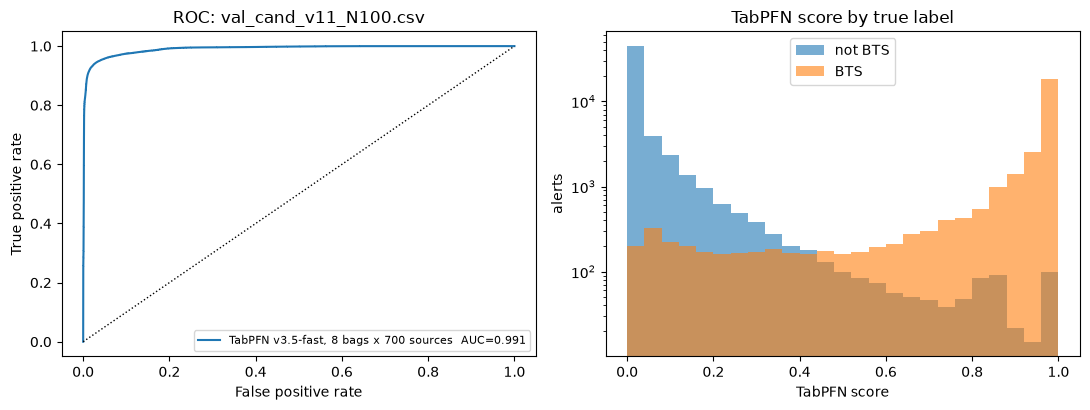

In [6]:
fig, (ax_roc, ax_hist) = plt.subplots(1, 2, figsize=(11, 4.2))

for name, col in scores.items():
    fpr, tpr, _ = roc_curve(y_eval, evaluation[col])
    ax_roc.plot(fpr, tpr, label=f"{name}  AUC={roc_auc_score(y_eval, evaluation[col]):.3f}")
ax_roc.plot([0, 1], [0, 1], "k:", lw=1)
ax_roc.set(xlabel="False positive rate", ylabel="True positive rate", title=f"ROC: {eval_name}")
ax_roc.legend(loc="lower right", fontsize=8)

bins = np.linspace(0, 1, 26)
ax_hist.hist(evaluation.tfm_score[evaluation.label == 0], bins=bins, alpha=0.6, label="not BTS")
ax_hist.hist(evaluation.tfm_score[evaluation.label == 1], bins=bins, alpha=0.6, label="BTS")
ax_hist.set(xlabel="TabPFN score", ylabel="alerts", title="TabPFN score by true label", yscale="log")
ax_hist.legend()
fig.tight_layout()

## Policy-based (per-source) metrics
The same computation `val.py` runs (`policy_metrics.compute_policy_performance_fast`): each policy accumulates a source's
alert-level predictions in time order into a single save decision, then precision/recall are counted over sources
(RCF junk, single-alert sources, and BTS sources that never got brighter than 18.5 are excluded). `save dt` / `trigger
dt` are days from the policy's first save to the scanners' save / trigger, for true positives with reliable times
(2021+); negative means the policy was earlier. `preds` are the scores rounded at 0.5, as in `val.py`.

Uses the vectorized `compute_policy_performance_fast`, which gives identical results to
`compute_policy_performance` in well under a second per model, even on the full `val_cand_v11`.

In [7]:
%%time
policy_cols = {"objectId", "jd", "label", "magpsf", "peakmag"}
if policy_cols - set(evaluation.columns):
    print(f"Skipping policy metrics: {EVAL_SPLIT} split is missing {sorted(policy_cols - set(evaluation.columns))}")
else:
    policy_performance = {}
    for name, col in scores.items():
        cand = evaluation.assign(raw_preds=evaluation[col], preds=np.rint(evaluation[col]).astype(int))
        _, policy_performance[name] = compute_policy_performance_fast(cand)

    policy_table = pd.DataFrame({
        (name, policy): {
            "precision": p["policy_precision"],
            "recall": p["policy_recall"],
            "median save dt (d)": p["med_save_dt"],
            "median trigger dt (d)": p["med_trigger_dt"],
        }
        for name, perf in policy_performance.items()
        for policy, p in perf.items()
    }).T
    display(policy_table.round(3))

Finished policy bts_p1 analysis


Finished policy bts_p2 analysis


Finished policy prod_p1 analysis


Finished policy prod_p2 analysis


precision  recall  \
TabPFN v3.5-fast, 8 bags x 700 sources bts_p1       0.917   0.985   
                                       bts_p2       0.959   0.985   
                                       prod_p1      0.981   0.955   
                                       prod_p2      0.983   0.955   

                                                median save dt (d)  \
TabPFN v3.5-fast, 8 bags x 700 sources bts_p1               -0.030   
                                       bts_p2                0.086   
                                       prod_p1              -0.050   
                                       prod_p2              -0.037   

                                                median trigger dt (d)  
TabPFN v3.5-fast, 8 bags x 700 sources bts_p1                   0.596  
                                       bts_p2                   1.861  
                                       prod_p1                  0.762  
                                       prod_p2                  1.676

CPU times: user 3min 59s, sys: 1.09 s, total: 4min
Wall time: 4min 2s


## What `lazy` actually returns: the full density
Each alert gets a distribution over the target. With a 0/1 target it should be two spikes, and the mass in the spike
near 1 is the score. This is mostly a sanity check here, but it's the main thing `lazy` adds over a plain classifier.
Skipped when bagging, since the bag models aren't kept.

In [8]:
if model is None:
    print("Bagging is on; skipping (bag models are freed after scoring).")
else:
    grid = np.linspace(-0.5, 1.5, 201)
    # most confident non-BTS, most confident BTS, most uncertain (drawn last so it's on top)
    examples = evaluation.loc[[
        evaluation.tfm_score.idxmin(),
        evaluation.tfm_score.idxmax(),
        (evaluation.tfm_score - 0.5).abs().idxmin(),
    ]]
    pdfs = model.predict_proba(examples[metadata_cols], y_grid=grid)

    fig, ax = plt.subplots(figsize=(6, 3.5))
    for (_, row), pdf in zip(examples.iterrows(), pdfs):
        ax.plot(grid, pdf, label=f"{row.objectId} (label={row.label}, score={row.tfm_score:.2f})")
    ax.set(xlabel="y", ylabel="p(y | x)", title="Predicted densities for three alerts")
    ax.legend(fontsize=8)
    fig.tight_layout()

Bagging is on; skipping (bag models are freed after scoring).
